In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('dmart_sales_cleaned.csv')

df.head()

,Order_ID,Order_Date,Store_ID,City,State,Customer_ID,Gender,Age,Segment,Phone,...,Product_Name,Category,Sub_Category,Quantity,MRP,Selling_Price,Cost_Price,Discount,Payment_Mode,Total_Amount
0,DM012717,25-10-2025,ST002,Ahmedabad,Gujarat,C01213,Female,56.0,Corporate,7.533064e+09,...,Colgate Toothpaste,Non-Foods,Personal Care,5.0,125,122.5,98,2,Debit Card,612.5
1,DM009023,18-11-2025,ST002,Ahmedabad,Gujarat,C02131,Other,67.0,Wholesale,NaN,...,Amul Taaza Milk,Foods,Dairy,3.0,65,57.2,54,12,UPI,171.6
2,DM007698,19-12-2025,ST010,Indore,Madhya Pradesh,C00405,Male,74.0,Retail,9.690169e+09,...,Aashirvaad Atta 5kg,Foods,Staples,4.0,285,228.0,238,20,Credit Card,912.0
3,DM007983,01-11-2025,ST008,Mumbai,Maharashtra,C02496,Female,24.0,Wholesale,9.497215e+09,...,India Gate Basmati Rice,Foods,Staples,4.0,620,589.0,535,5,Net Banking,2356.0
4,DM005212,10-05-2025,ST010,Surat,Gujarat,C06025,Male,53.0,Corporate,7.018165e+09,...,Surf Excel Detergent,Non-Foods,Home Care,1.0,390,390.0,332,0,UPI,390.0


In [7]:
print(df.shape)

(30000, 21)


In [8]:
df.columns

Index(['Order_ID', 'Order_Date', 'Store_ID', 'City', 'State', 'Customer_ID',
       'Gender', 'Age', 'Segment', 'Phone', 'Product_ID', 'Product_Name',
       'Category', 'Sub_Category', 'Quantity', 'MRP', 'Selling_Price',
       'Cost_Price', 'Discount', 'Payment_Mode', 'Total_Amount'],
      dtype='str')

In [9]:
print(df.duplicated().sum())

0


In [12]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')

In [13]:
df['Order_Date'].dtype

dtype('<M8[us]')

In [14]:
df['Order_Date'].dtype

dtype('<M8[us]')

In [15]:
df['Month'] = df['Order_Date'].dt.month_name()
df[['Order_Date', 'Month']].head()

,Order_Date,Month
0,2025-10-25,October
1,2025-11-18,November
2,2025-12-19,December
3,2025-11-01,November
4,2025-05-10,May


In [16]:
df

,Order_ID,Order_Date,Store_ID,City,State,Customer_ID,Gender,Age,Segment,Phone,...,Category,Sub_Category,Quantity,MRP,Selling_Price,Cost_Price,Discount,Payment_Mode,Total_Amount,Month
0,DM012717,2025-10-25,ST002,Ahmedabad,Gujarat,C01213,Female,56.0,Corporate,7.533064e+09,...,Non-Foods,Personal Care,5.0,125,122.50,98,2,Debit Card,612.5,October
1,DM009023,2025-11-18,ST002,Ahmedabad,Gujarat,C02131,Other,67.0,Wholesale,NaN,...,Foods,Dairy,3.0,65,57.20,54,12,UPI,171.6,November
2,DM007698,2025-12-19,ST010,Indore,Madhya Pradesh,C00405,Male,74.0,Retail,9.690169e+09,...,Foods,Staples,4.0,285,228.00,238,20,Credit Card,912.0,December
3,DM007983,2025-11-01,ST008,Mumbai,Maharashtra,C02496,Female,24.0,Wholesale,9.497215e+09,...,Foods,Staples,4.0,620,589.00,535,5,Net Banking,2356.0,November
4,DM005212,2025-05-10,ST010,Surat,Gujarat,C06025,Male,53.0,Corporate,7.018165e+09,...,Non-Foods,Home Care,1.0,390,390.00,332,0,UPI,390.0,May
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,DM009895,2025-09-14,ST001,Ahmedabad,Gujarat,C00937,Female,25.0,Wholesale,NaN,...,Foods,Staples,2.0,285,279.30,238,2,Debit Card,558.6,September
29996,DM010375,2025-11-13,ST001,Thane,Maharashtra,C00643,Female,39.0,Retail,9.369143e+09,...,Foods,Staples,6.0,145,123.25,119,15,Debit Card,739.5,November
29997,DM014441,2025-12-31,ST003,Nagpur,Maharashtra,C00738,Female,18.0,Corporate,NaN,...,Non-Foods,Personal Care,10.0,520,478.40,438,8,Net Banking,4784.0,December
29998,DM010900,2025-11-15,ST007,Thane,Maharashtra,C01974,Male,55.0,Retail,NaN,...,Foods,Packaged Foods,1.0,56,56.00,43,0,UPI,56.0,November


In [17]:
df['Profit'] = (df['Selling_Price'] - df['Cost_Price']) * df['Quantity']

df[['Selling_Price', 'Cost_Price', 'Quantity', 'Profit']].head()

,Selling_Price,Cost_Price,Quantity,Profit
0,122.5,98,5.0,122.5
1,57.2,54,3.0,9.6
2,228.0,238,4.0,-40.0
3,589.0,535,4.0,216.0
4,390.0,332,1.0,58.0


In [18]:
print("Total Sales:", df['Total_Amount'].sum())

Total Sales: 41578401.05


In [19]:
total_sales = df['Total_Amount'].sum()
print("Total Sales:", total_sales)

Total Sales: 41578401.05


In [20]:
print('Total profit :',round(df['Profit'].sum(),2))

Total profit : 6452513.05


In [21]:
total_orders = df['Order_ID'].nunique()
print("Total Orders:", total_orders)

Total Orders: 14907


In [22]:
total_customers = df['Customer_ID'].nunique()
print("Total Customers:", total_customers)

Total Customers: 6438


In [23]:
average_order_value = total_sales / total_orders
print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 2789.19


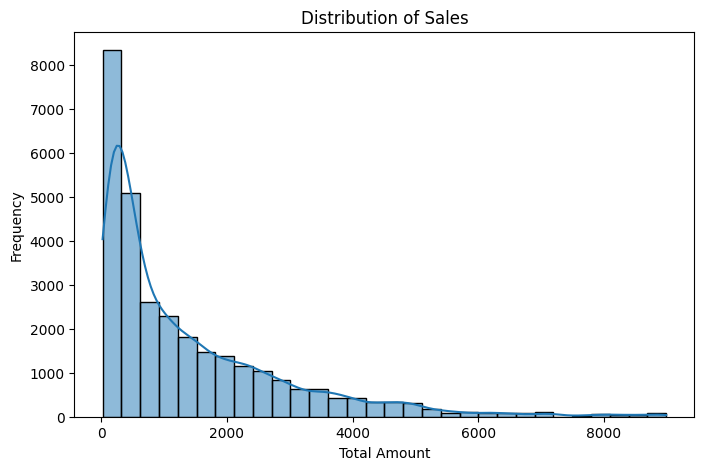

In [24]:
# sales distribution

plt.figure(figsize=(8, 5))
sns.histplot(df['Total_Amount'], bins=30, kde=True)
plt.title('Distribution of Sales')
plt.xlabel('Total Amount')
plt.ylabel('Frequency')
plt.show()

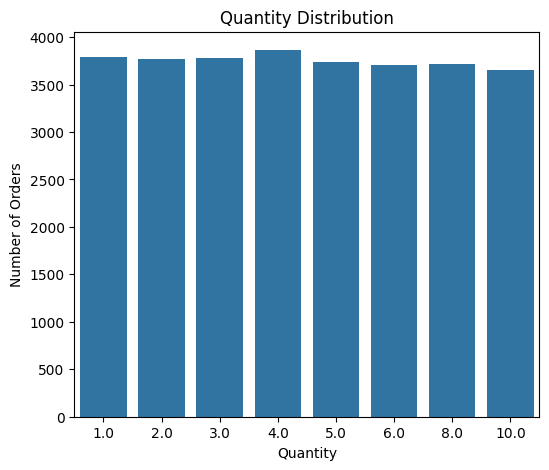

In [25]:
# quantity distribution 

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x='Quantity')
plt.title('Quantity Distribution')
plt.xlabel('Quantity')
plt.ylabel('Number of Orders')
plt.show()

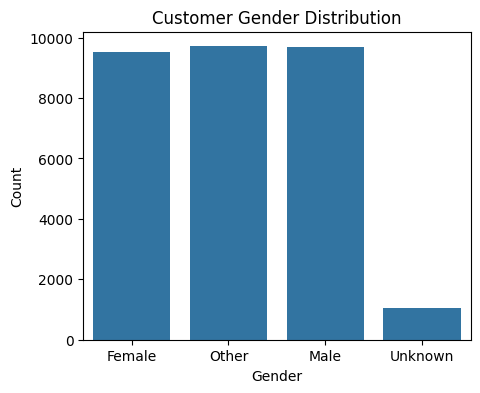

In [26]:
# gender distribution 

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='Gender')
plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

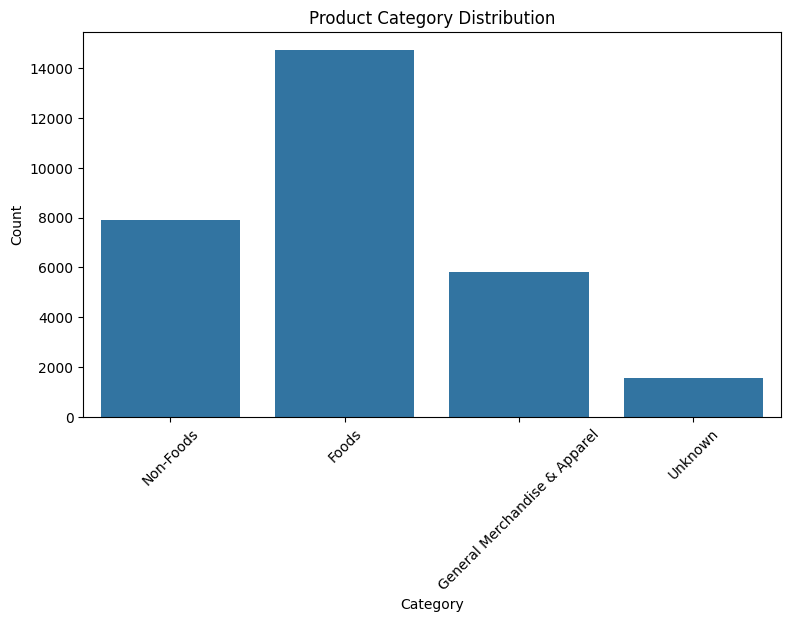

In [27]:
# product category distribution

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Category')
plt.title('Product Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

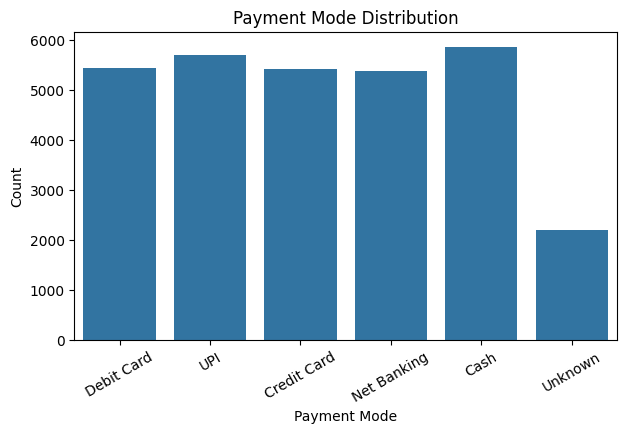

In [28]:
# payment mode distribution

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Payment_Mode')
plt.title('Payment Mode Distribution')
plt.xlabel('Payment Mode')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.show()

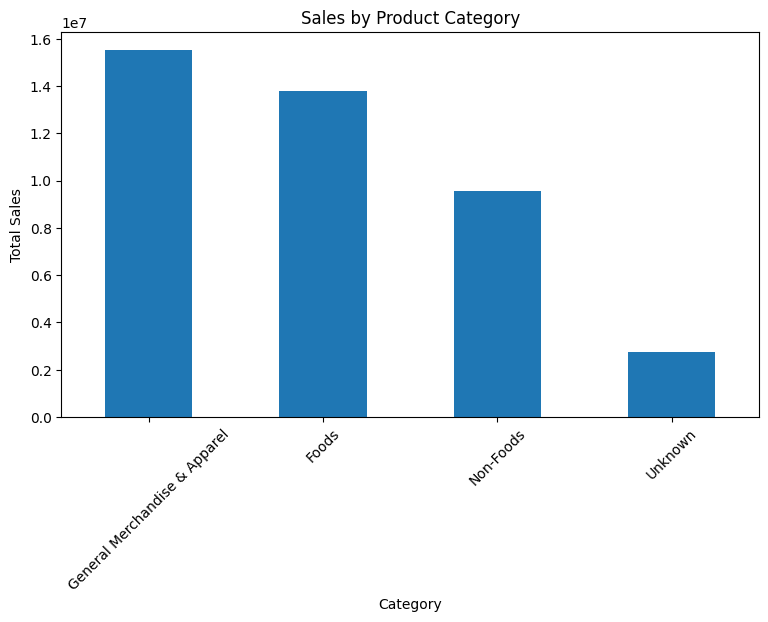

In [29]:
# sales by category 

category_sales = df.groupby('Category')['Total_Amount'].sum().sort_values(ascending=False)
category_sales.plot(kind='bar', figsize=(9, 5))
plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.show()

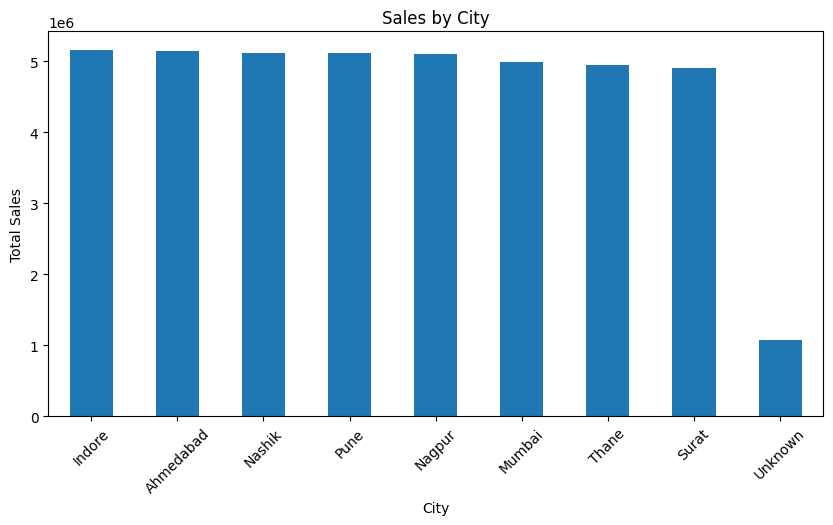

In [30]:
# sales by city 

city_sales = df.groupby('City')['Total_Amount'].sum().sort_values(ascending=False)
city_sales.plot(kind='bar', figsize=(10, 5))
plt.title('Sales by City')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

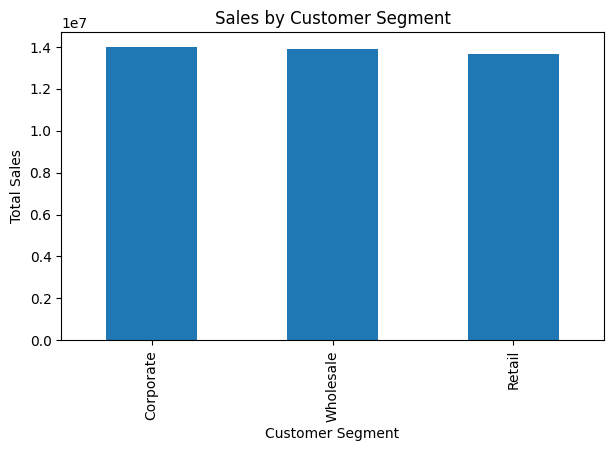

In [31]:
# sales by customer segment

segment_sales = df.groupby('Segment')['Total_Amount'].sum().sort_values(ascending=False)
segment_sales.plot(kind='bar', figsize=(7, 4))
plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.show()

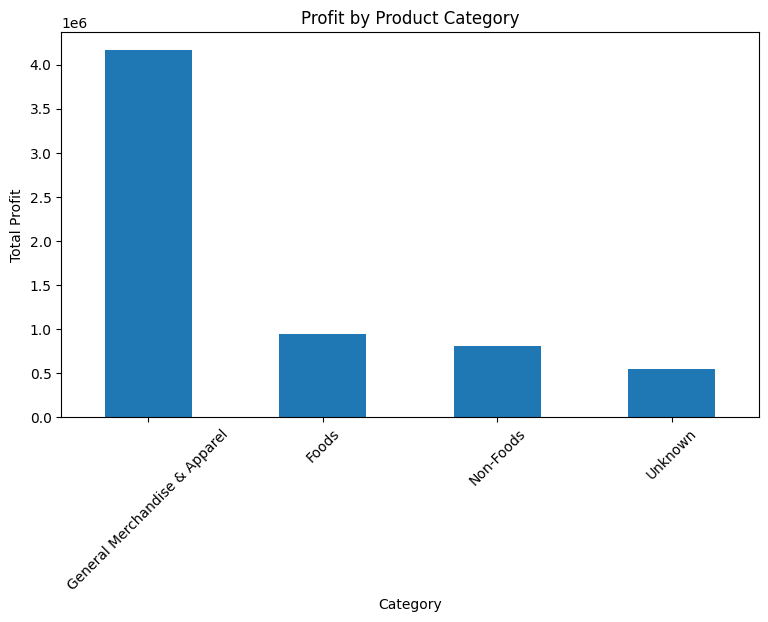

In [32]:
# profit by product category 

category_profit = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)

category_profit.plot(kind='bar', figsize=(9, 5))

plt.title('Profit by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)

plt.show()

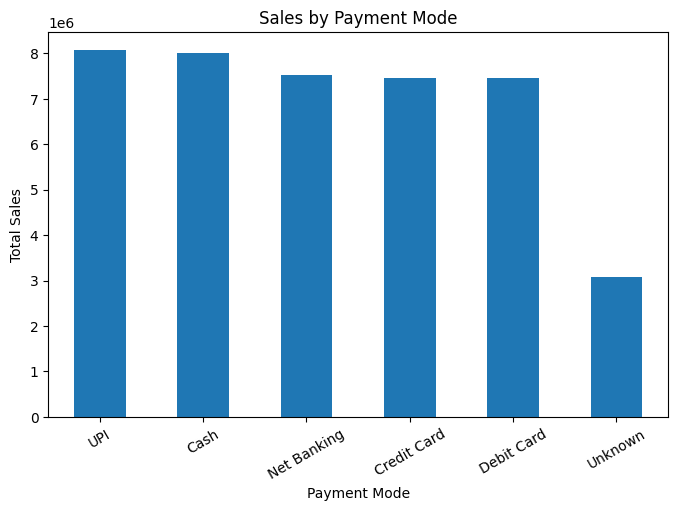

In [33]:
# sales by payment method

payment_sales = df.groupby('Payment_Mode')['Total_Amount'].sum().sort_values(ascending=False)

payment_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by Payment Mode')
plt.xlabel('Payment Mode')
plt.ylabel('Total Sales')
plt.xticks(rotation=30)

plt.show()

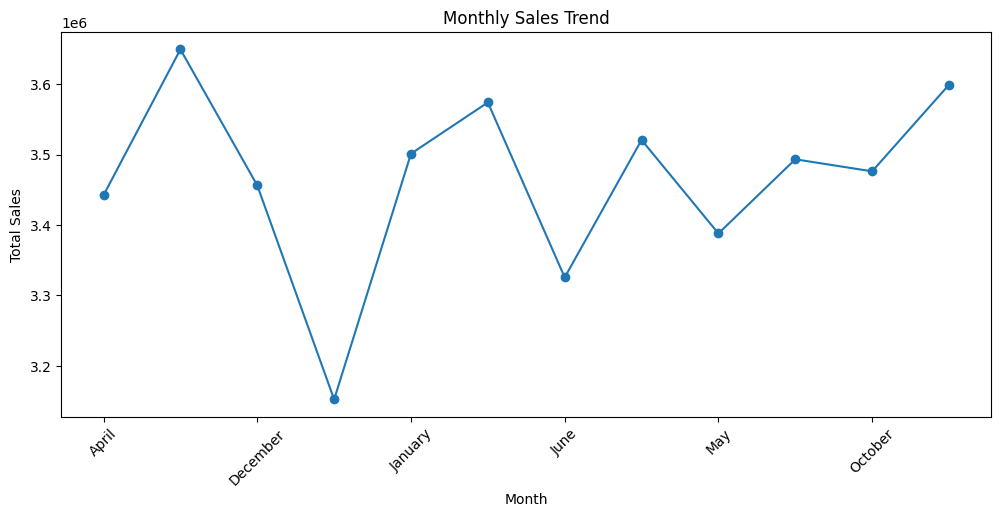

In [34]:
# monthly sales trend 

monthly_sales = df.groupby('Month')['Total_Amount'].sum()

monthly_sales.plot(kind='line', marker='o', figsize=(12, 5))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.show()

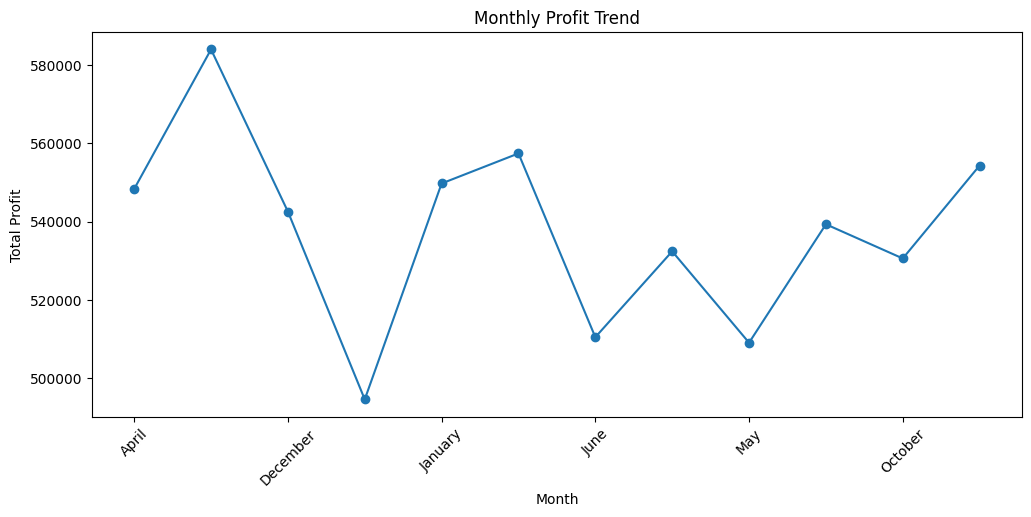

In [35]:
# monthly profit trend 

monthly_profit = df.groupby('Month')['Profit'].sum()
monthly_profit.plot(kind='line', marker='o', figsize=(12, 5))
plt.title('Monthly Profit Trend')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.show()

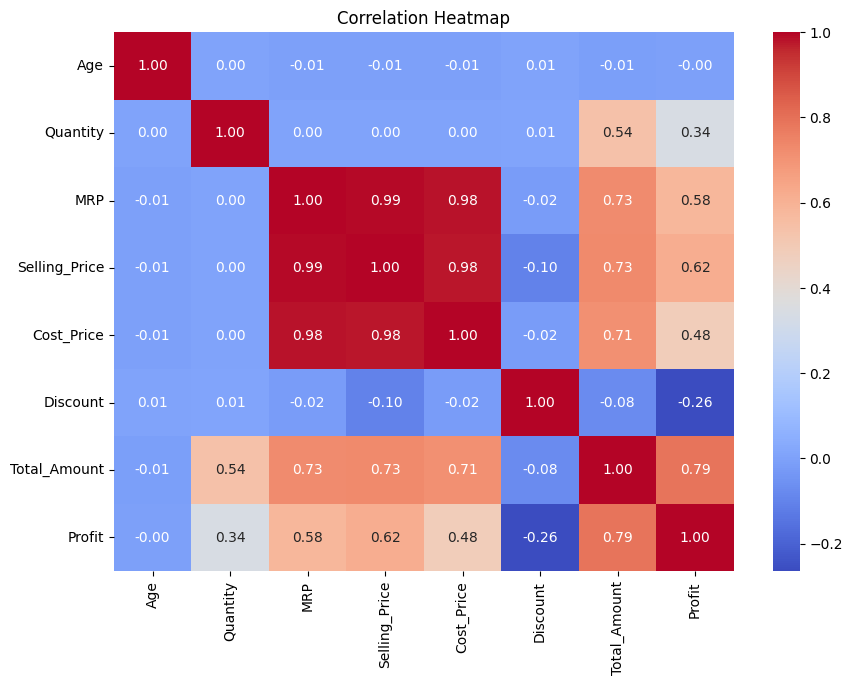

In [36]:
numeric_columns = [
    'Age', 'Quantity', 'MRP',
    'Selling_Price', 'Cost_Price',
    'Discount', 'Total_Amount', 'Profit'
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

In [37]:
# top 10 product by sales 

top_products = df.groupby('Product_Name')['Total_Amount'].sum().sort_values(ascending=False).head(10)
print(top_products)

Product_Name
Cotton Bedsheet            8582303.50
India Gate Basmati Rice    6035166.80
Dove Shampoo               5001760.40
Cotton T-shirt             4860674.17
Steel Water Bottle         3823010.52
Surf Excel Detergent       3573113.70
Amul Butter                2672561.85
Aashirvaad Atta 5kg        2612415.45
Fortune Sunflower Oil      1376738.75
Colgate Toothpaste         1142156.25
Name: Total_Amount, dtype: float64


In [38]:
# top 10 cities by sales 

top_cities = df.groupby('City')['Total_Amount'].sum().sort_values(ascending=False).head(10)
print(top_cities)

City
Indore       5165210.03
Ahmedabad    5151952.80
Nashik       5124226.61
Pune         5123603.62
Nagpur       5102637.43
Mumbai       4986423.82
Thane        4943728.24
Surat        4911572.31
Unknown      1069046.19
Name: Total_Amount, dtype: float64


In [39]:
# average sales by customer segment 
average_segment_sales = df.groupby('Segment')['Total_Amount'].mean().sort_values(ascending=False)
print(average_segment_sales)

Segment
Wholesale    1387.297432
Retail       1387.089293
Corporate    1383.496211
Name: Total_Amount, dtype: float64
